# 1️⃣ Introduction 🖊️

Author: Bara Samudra Syuhada

Notebook ini berisi analisis data dengan statistik dan visualisasi data terhadap data survey kepuasan pelanggan di suatu maskapai penerbangan

# 2️⃣ Problem Statement and Data Description ✈️

## Topik

Analisis data secara statistik dan visualisasi data survey kepuasan pelanggan maskapai penerbangan

## Problem Statement

Mengetahui faktor yang berperan terhadap kepuasan customer maskapai X untuk mengingkatkan kualitas pelayanan maskapai agar tingkat kepuasan pelanggan meningkat 20% di tahun depan

## Latar Belakang

Saya merupakan seorang Data Analyst yang bekerja di bawah divisi *flight coordination* untuk maskapai X. Divisi ini berperan sebagai koordinator penerbangan seperti menghubungkan seluruh unit di darat agar jadwal penerbangan tepat waktu dan membantu persiapan rencana terbang termasuk jalur penerbangan. Divisi pemasaran baru-baru ini melakukan survey kepuasan penumpang dengan penerbangan mereka. Mereka ingin mengethaui kenapa lebih banyak pelanggan yang tidak puas dengan maskapai X dan ingin meningkatkan satisfaction rate pelanggan. Selanjutnya mereka menginginkan data analyst dari berbagai divisi, termasuk divisi *flight coordination* untuk mengolah data survey tersebut dan memberikan insight dari hasil analisis sebagai bahan pertimbangan mereka untuk mencari tahu lebih lanjut terkait faktor apa yang paling berperan terhadap kepuasan pelanggan.

## Sumber Dataset

Dataset di publish di Kaggle oleh Arseniy Shutko. Data tersebut merupakan hasil survey anonim yang dilakukan oleh suatu maskapai penerbangan terhadap kepuasan para penumpang maskapai tersebut.

Berikut link dataset yang digunakan: \
https://www.kaggle.com/datasets/arseniyshutko/binary-aviation-satisfaction-129k

Adapun dataset terdiri atas 22 kolom sebagai berikut:

**Informasi Penumpang** \
**Gender**: jenis kelamin penumpang (Male/Female) \
**Customer Type**: tipe penumpang (Loyal/Disloyal) \
**Age**: usia penumpang (numerical) \
**Type of Travel**: tujuan berpergian (Personal/Business) \
**Class**: kelas penerbangan (Business/Eco/Eco Plus) \
**Flight Distance**: jarak penerbangan dalam mil (numerical)

**Rating kualitas layanan (1-5) atau 0 (0 = tidak memberi rating)** \
**Inflight wifi service**: kepuasan dengan wifi di pesawat \
**Departure/Arrival time convenient**: kepuasaan dengan waktu keberangkatan/kedatangan \
**Ease of Online Booking**: kepuasan dengan proses booking online \
**Gate location**: kepuasan dengan lokasi gate \
**Food and drink**: kepuasan dengan makanan dan minuman yang disediakan maskapai \
**Online boarding**: kepuasan dengan online check-in \
**Seat comfort**: kepuasan dengan kenyamanan seat penumpang \
**Inflight entertainment**: kepuasan dengan pilihan hiburan dalam pesawat \
**On-board service**: kepuasan dengan pelayanan saat penerbangan \
**Leg room service**: kepuasan dengan layanan legroom \
**Baggage handling**: kepuasan dengan penanganan bagasi \
**Checkin service**: kepuasan dengan layanan check-in \
**Cleanliness**: kepuasan dengan kebersihan kabin 

**Waktu delay** \
**Departure Delay in Minutes**: delay keberangkatan \
**Arrival Delay in Minutes**: delay kedatangan 

**Kepuasan Pelanggan** \
**Satisfaction**: True = puas, False = tidak puas

## Penjabaran masalah

1. Bagaimana kepuasan penumpang berdasarkan kelas penerbangan dan tipe perjalanan penumpang?
2. Bagaimana penilaian penumpang terhadap kenyamanan waktu keberangkatan berdasarkan tipe penumpang?
3. Bagaimana hubungan antara jarak penerbangan dengan waktu delay keberangkatan dan kedatangan?
4. Apakah durasi keterlambatan keberangkatan dan kedatangan berpengaruh secara signifikan terhadap rating kepuasan penumpang terhadap kenyamanan waktu penerbangan?
5. Bagaimana central tendency dan distribusi dari waktu keterlambatan kebarangkatan dan kedatangan?
6. Apakah tingkat kepuasan penumpang dengan tujuan bisnis dan tujuan personal terhadap kenyamanan waktu penerbangan berbeda?

# 3️⃣ Data Loading 💾

In [76]:
# import library
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# load data
df = pd.read_csv('P0M1_bara_dataset.csv')

# lihat 10 baris pertama data
df.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True


In [3]:
# melihat informasi rangkuman data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    1298

Data survey kepuasan penumpang memiliki 129.880 baris dengan 22 kolom. Kolom "Gender", "Customer Type", "Type of Traveler", dan "Class" bertipe string atau object, kolom "Arrival Delay in Minutes" bertipe data float, kolom "satisfaction" bertipe data boolean, dan sisanya bertipe data integer. Selanjutnya, akan dilakukan cleaning data dengan menghapus kolom yang tidak digunakan dan mengecek serta handle missing value

# 4️⃣ Data Cleaning 🧹

Di divisi Flight Coordination, tugas kita hanyalah menangani data yang berkaitan dengan rencana penerbangan seperti penjadwalan terbang. Oleh karena itu, divisi ini hanya akan menganalisis data kepuasan terkait "Departure/Arrival time convenient". Oleh karena itu akan dilakukan cleaning data dengan membuang kolom yang tidak perlu dan menyisakan kolom informasi penumpang ("Gender", "Customer Type", "Age", "Type of Travel", "Class", "Flight Distance"), kolom "Departure/Arrival time convenient", "Departure Delay in Minutes", "Arrival Delay in Minutes", dan "satisfaction"

In [11]:
# membuat dataframe baru yang hanya berisikan kolom yang sekiranya dibutuhkan
df_new = df[["Gender", "Customer Type", "Age", "Type of Travel", "Class", "Flight Distance", "Departure/Arrival time convenient", "Departure Delay in Minutes", "Arrival Delay in Minutes", "satisfaction"]]

# menampilkan 10 data pertama
df_new.head(10)

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Departure/Arrival time convenient,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,4,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,2,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,5,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,0,0.0,True
5,Female,Loyal Customer,26,Personal Travel,Eco,1180,4,0,0.0,False
6,Male,Loyal Customer,47,Personal Travel,Eco,1276,4,9,23.0,False
7,Female,Loyal Customer,52,Business travel,Business,2035,3,4,0.0,True
8,Female,Loyal Customer,41,Business travel,Business,853,2,0,0.0,False
9,Male,disloyal Customer,20,Business travel,Eco,1061,3,0,0.0,False


In [ ]:
# melihat banyaknya NULL value
df_new.isna().sum()

Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Departure/Arrival time convenient      0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393
satisfaction                           0
dtype: int64

Pada data ini, terdapat 393 missing values. Dalam hal ini, kita akan membuang saja setiap baris yang memiliki missing value. Hal ini dikarenakan kita tidak ingin mengasumsikan jika "Arrival Delay in Minutes" kosong berarti tidak terjadi delay.

In [15]:
# membuang baris dengan missing value

df_clean = df_new.dropna()

# melihat informasi clean data

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 129487 entries, 0 to 129879
Data columns (total 10 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129487 non-null  object 
 1   Customer Type                      129487 non-null  object 
 2   Age                                129487 non-null  int64  
 3   Type of Travel                     129487 non-null  object 
 4   Class                              129487 non-null  object 
 5   Flight Distance                    129487 non-null  int64  
 6   Departure/Arrival time convenient  129487 non-null  int64  
 7   Departure Delay in Minutes         129487 non-null  int64  
 8   Arrival Delay in Minutes           129487 non-null  float64
 9   satisfaction                       129487 non-null  bool   
dtypes: bool(1), float64(1), int64(4), object(4)
memory usage: 10.0+ MB


Setelah dilakukan cleaning data, diperoleh 129.487 baris dengan 10 kolom.

In [17]:
# cek jumlah missing value untuk memastikan

df_clean.isna().sum()

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Departure/Arrival time convenient    0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64

Dataset setalah dilakukan cleaning akan diekspor ke csv agar dapat divisualisasikan juga menggunakan Tableau

In [78]:
# ekspor df_clean ke csv
df_clean.to_csv("P0M1_bara_clean_dataset.csv")

# 5️⃣ Data Analysis 📊

## 1.

Setelah data direduksi menjadi data yang informasinya diperlukan, kita akan mulai menganalisis data tersebut untuk memperoleh insight yang berkaitan dengan divisi flight coordination. Pertama-tama kita akan melihat kepuasan pelanggan ("satisfaction") secara umum berdasarkan kelas penerbangan ("Class") dan tujuan berpergian ("Type of Travel") dari penumpang

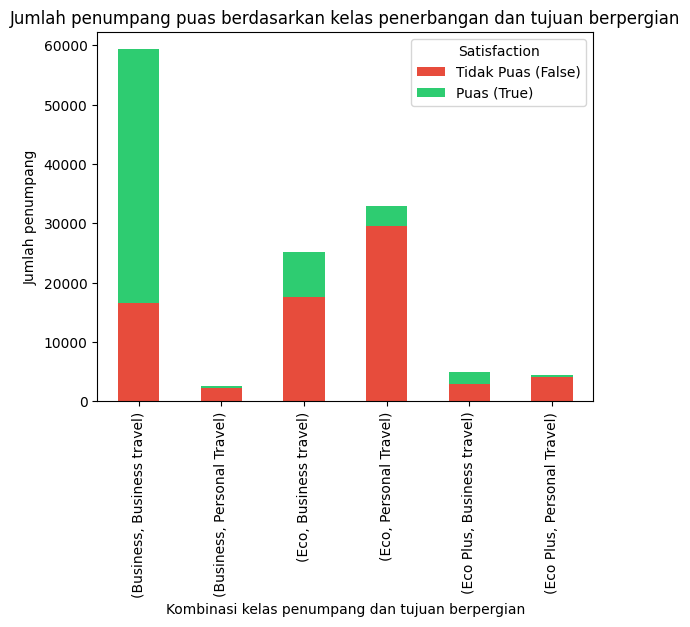

In [45]:
# mendefinisikan cross table (tabel frekuensi untuk kategori tertentu) dengan fungsi crosstab
data = pd.crosstab(index = [df_clean['Class'], df_clean['Type of Travel']], columns = df_clean['satisfaction'])

# mendefinisikan warna bar
color_map = {True: '#2ecc71', False: '#e74c3c'} # True = Hijau, False = Merah
colors = [color_map[col] for col in data.columns]

# membuat stacked bar chart
fig, ax = plt.subplots()
data.plot(kind='bar', stacked = 'True', color=colors, ax=ax)

# penambahan judul grafik dan lain-lain
plt.title( 'Jumlah penumpang puas berdasarkan kelas penerbangan dan tujuan berpergian')
plt.xlabel('Kombinasi kelas penumpang dan tujuan berpergian')
plt.ylabel('Jumlah penumpang')
plt.legend(title='Satisfaction', labels=['Tidak Puas (False)', 'Puas (True)'])

plt.show()

Berdasarkan visualisasi data, dapat dilihat bahwa lebih banyak penumpang yang merasa tidak puas untuk tujuan berpergian "personal" di semua kelas. Sementara itu, untuk penumpang dengan tujuan berpergian "bisnis" lebih banyak yang merasa tidak puas di kelas ekonomi dan ekonomi plus. Untuk penumpang di kelas bisnis dengan tujuan berpergian "bisnis" terlihat bahwa lebih banyak yang merasa puas. Meskipun begitu, jumlah penumpang tidak puas untuk kategori tersebut masih cukup banyak (lebih dari 1500 penumpang) 

## 2.

Selanjutnya, ingin diketahui bagaimana penilaian penumpang terhadap kenyamanan waktu keberangkatan berdasarkan tipe penumpang 

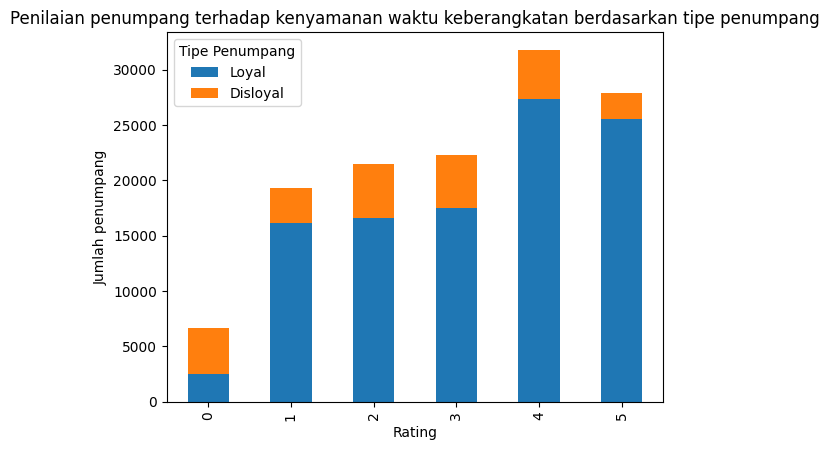

In [47]:
# mendefinisikan cross table dengan "Departure/Arrival time convenient" dan "Costumer Type" sebagai kolom
data2 = pd.crosstab(index = df_clean['Departure/Arrival time convenient'], columns = df_clean['Customer Type'])

# membuat stacked bar chart
fig, ax = plt.subplots()
data2.plot(kind='bar', stacked = 'True', 
          ax=ax)

# penambahan judul grafik dan lain-lain
plt.title( 'Penilaian penumpang terhadap kenyamanan waktu keberangkatan berdasarkan tipe penumpang')
plt.xlabel('Rating')
plt.ylabel('Jumlah penumpang')
plt.legend(title='Tipe Penumpang', labels=['Loyal', 'Disloyal'])

plt.show()

Dari hasil visualisasi tersebut kita dapat melihat bahwa penumpang penumpang loyal lebih banyak yang memberikan rating tinggi (4 & 5), sedangkan penumpang disloyal lebih banyak memberikan rating 2 atau 3. Meskipun begitu, frekuensi penumpang loyal lebih banyak dibandingkan disloyal. Namun secara keseluruhan, secara visualisasi rating tinggi (4 & 5) bisa jadi masih kurang atau sama dengan jumlah rating lainnya (1, 2, dan 3) jika digabungkan. Selain itu, terdapat lebih dari 5000 orang yang tidak memberikan rating (0)

## 3.

Selanjutnya kita ingin mengetahui apakah ada hubungan antara jarak tempuh perjalanan dengan keterlambatan keberangkatan dan kedatangan. Oleh karena itu, hubungan antara jarak tempuh dengan keterlambatan keberangkatan dan kedatangan akan divisualisasikan dalam bentuk scatter plot

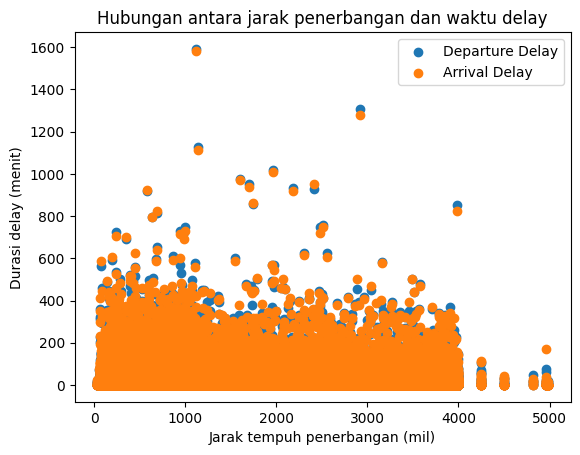

In [44]:
# visualisasi hubungan jarak tempuh penerbangan (mil) dan keterlambatan (menit)
fig, ax = plt.subplots()
#ax.plot(df["Flight Distance"], df["Departure Delay in Minutes"], label = "Departure Delay")
#ax.plot(df["Flight Distance"], df["Arrival Delay in Minutes"], label = "Arrival Delay")

ax.scatter(df_clean["Flight Distance"], df_clean["Departure Delay in Minutes"], label = "Departure Delay")
ax.scatter(df_clean["Flight Distance"], df_clean["Arrival Delay in Minutes"], label = "Arrival Delay")

ax.set_xlabel("Jarak tempuh penerbangan (mil)")
ax.set_ylabel("Durasi delay (menit)")

ax.set_title("Hubungan antara jarak penerbangan dan waktu delay")

plt.legend()
plt.show()

Dari visualisasi di atas dapat dilihat bahwa sebetulnya tidak ada hubungan antara jarak tempuh penerbangan dan waktu keterlambatan (keberangkatan atau kedatangan). Namun, dari sini bisa dilihat bahwa terdapat data outlier, di mana keterlambatan yang paling parah bisa mencapai sekitar 1600 menit atau sekitar satu hari lebih.

## 4.

Selanjutnya kita akan melihat apakah durasi delay keterlambatan keberangkatan dan kedatangan berpengaruh terhadap penilaian kenyamanan waktu penerbangan oleh penumpang.

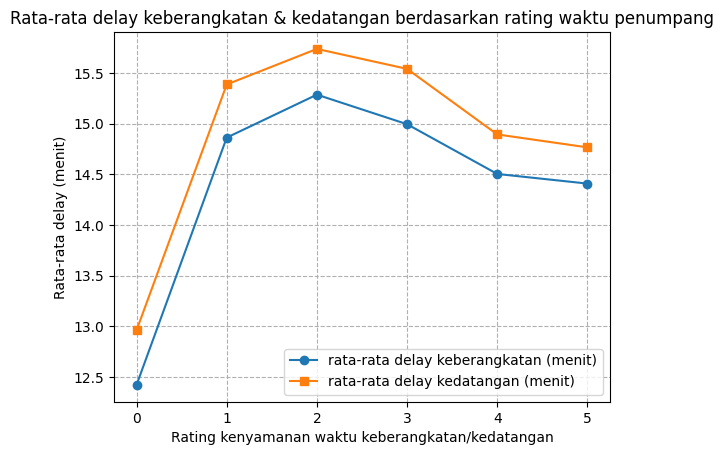

In [63]:
# mendefinisikan tabel agregat berisi rata-rata delay keberangkatan dan kedatangan yang dikelompokkan berdasarkan rating

df_groupped = df_clean.groupby("Departure/Arrival time convenient")[["Departure Delay in Minutes","Arrival Delay in Minutes"]].mean().reset_index()

# membuat line chart
plt.plot(df_groupped["Departure/Arrival time convenient"], df_groupped["Departure Delay in Minutes"], marker = 'o', label = 'rata-rata delay keberangkatan (menit)')
plt.plot(df_groupped["Departure/Arrival time convenient"], df_groupped["Arrival Delay in Minutes"], marker = 's', label = 'rata-rata delay kedatangan (menit)')

# Judul grafik dan keterangan sumbu x dan y
plt.title("Rata-rata delay keberangkatan & kedatangan berdasarkan rating waktu penumpang")
plt.xlabel("Rating kenyamanan waktu keberangkatan/kedatangan")
plt.ylabel('Rata-rata delay (menit)')

# menambahkan grid chart untuk memudahkan interpretasi
plt.grid(True, linestyle='--')

# menampilkan grafik 
plt.legend()
plt.show()

Berdasarkan visualisasi yang dilihat bisa disimpulkan bahwa tidak ada perbedaan rata-rata waktu keterlambatan penerbangan untuk setiap kelompok rating yang diberikan oleh penumpang. Perbedaan paling mencolok adalah saat rating = 0 dimana rata-rata waktu keterlambatan sekitar 12,5 menit untuk keberangkatan dan sekitar 13 menit untuk kedatangan. Namun, rating 0 menunjukkan bahwa penumpang tersebut tidak memberikan penilaian terhadap indikator kenyamanan terhadap waktu penerbangan sehingga tidak dapat disimpulkan apa pun. Dari segi operasional, perbedaan waktu keterlambatan hingga 1 menit juga tidak mengindikasikan adanya hubungan antara rata-rata waktu delay dengan rating karena perbedaan tersebut tidak terlalu signifikan

## 5.

Selanjutnya kita akan melihat bagaimana central tendency dan distribusi durasi keterlambatan dan keberangkatan penerbangan untuk melihat seberapa lama biasanya maskapai X mengalami delay.

In [36]:
# central tendency durasi keterlambatan keberangkatan
print(f"rata-rata keterlambatan keberangkatan adalah sebanyak {df_clean['Departure Delay in Minutes'].mean():.2f} menit")
print(f"median keterlambatan keberangkatan adalah sebanyak {df_clean['Departure Delay in Minutes'].median():.2f} menit")
print(f"modus keterlambatan keberangkatan adalah sebanyak {df_clean['Departure Delay in Minutes'].mode().values[0]:.2f} menit")

# central tendency durasi keterlambatan kedatangan
print(f"rata-rata keterlambatan kedatangan adalah sebanyak {df_clean['Arrival Delay in Minutes'].mean():.2f} menit")
print(f"median keterlambatan kedatangan adalah sebanyak {df_clean['Arrival Delay in Minutes'].median():.2f} menit")
print(f"modus keterlambatan kedatangan adalah sebanyak {df_clean['Arrival Delay in Minutes'].mode().values[0]:.2f} menit")

rata-rata keterlambatan keberangkatan adalah sebanyak 14.64 menit
median keterlambatan keberangkatan adalah sebanyak 0.00 menit
modus keterlambatan keberangkatan adalah sebanyak 0.00 menit
rata-rata keterlambatan kedatangan adalah sebanyak 15.09 menit
median keterlambatan kedatangan adalah sebanyak 0.00 menit
modus keterlambatan kedatangan adalah sebanyak 0.00 menit


Berdasarkan central tendency tersebut, dapat kita ketahui bahwa ada 50% atau lebih dari penerbangan maskapai X yang tepat waktu baik keberangkatan maupun kedatangannya. Hal ini dikarenaka nilai median dari kedua data adalah 0 menit. Namun rata-rata keterlambatan sekitar 15 menit untuk keberangkatan dan kedatangan dapat mengindikasikan bahwa ada beberapa penerbangan yang mengalami delay cukup lama. Selanjutnya, akan dilihat sebaran data (standar deviasi) dan dilakukan normality test (skew dan kurtosis) untuk melihat bagaimana distribusi keterlambatan keberangkatan dan kedatangan.

In [37]:
# standar deviasi dan normality test keterlambatan keberangkatan
print(f"standar deviasi keterlambatan keberangkatan adalah adalah {df_clean['Departure Delay in Minutes'].std():.2f}")
print(f"skewness keterlambatan keberangkatan adalah {df_clean['Departure Delay in Minutes'].skew():.2f}")
print(f"kurtosis keterlambatan keberangkatan adalah {df_clean['Departure Delay in Minutes'].kurtosis():.2f}")

# standar deviasi dan normality test keterlambatan kedatangan
print(f"standar deviasi keterlambatan kedatangan adalah {df_clean['Arrival Delay in Minutes'].std():.2f}")
print(f"skewness keterlambatan kedatangan adalah {df_clean['Arrival Delay in Minutes'].skew():.2f}")
print(f"kurtosis keterlambatan kedatangan adalah {df_clean['Arrival Delay in Minutes'].kurtosis():.2f}")

standar deviasi keterlambatan keberangkatan adalah adalah 37.93
skewness keterlambatan keberangkatan adalah 6.85
kurtosis keterlambatan keberangkatan adalah 101.88
standar deviasi keterlambatan kedatangan adalah 38.47
skewness keterlambatan kedatangan adalah 6.67
kurtosis keterlambatan kedatangan adalah 95.12


Standar deviasi keterlambatan keberangkatan dan kedatangan yang lebih besar dari mean menunjukkan bahwa data tidak terdistribusi normal. Ini dapat diartikan data menumpuk di 0 (karena modus 0) dan memiliki nilai ekstrim. Sisi positif dari hal ini adalah, jadwal penerbangan maskapai X lebih sering tepat waktu atau mengalami keterlambatan selama 14.64 ± 37.93 menit untuk keberangkatan dan 15.09 ± 38.47 menit untuk kedatangan. Namun, sisi negatif dari hasil analisis statistik ini adalah data terindikasi memiliki outlier yang signifikan yang dibuktikan dengan nilai kurtosis (101.88 untuk delay keberangkatan dan 95.12 untuk delay kedatangan). Ini menunjukkan bahwa terdapat penerbangan yang memiliki waktu keterlambatan yang cukup lama. Adapun dengan nilai skew sebesar 6.85 dan 6.67 untuk delay keberangkatan dan kedatangan menunjukkan bahwa data tidak terdistribusi secara simetris. Hal ini sesuai dengan interpretasi seblumnya, bahwa meskipun maskapai X lebih banyak melakukan penerbangan tepat waktu, namun masih ada beberapa penerbangan yang terlambat cukup lama atau delay.

## 6.

Selanjutnya ingin diketahui apakah rata-rata rating penumpang terhadap kenyamanan waktu penerbangan dari penumpang dengan tujuan bisnis dan tujuan personal  berbeda. Untuk hal tersebut akan dilakukan uji hipotesis Two-Sample Independent Test dengan hipotesis sebagai berikut:

H0: Rata-rata rating kenyamanan waktu penerbangan penumpang dengan tujuan bisnis sama dengan rata-rata rating kenyamanan waktu penerbangan penumpang dengan tujuan personal

H1: Rata-rata rating kenyamanan waktu penerbangan penumpang dengan tujuan bisnis berbeda dengan rata-rata rating kenyamanan waktu penerbangan penumpang dengan tujuan personal

In [75]:
# filter data penumpang dengan tujuan bisnis dan personal
business_purpose = df_clean[(df_clean["Type of Travel"] == 'Business travel')]
personal_purpose = df_clean[(df_clean["Type of Travel"] == 'Personal Travel')]

# T-statistics Two-Sample Independent Test dengan α = 0.05
t_stat, p_val = stats.ttest_ind(business_purpose["Departure/Arrival time convenient"], personal_purpose["Departure/Arrival time convenient"], alternative = "two-sided", equal_var = False)
print("T-Statistics: ",t_stat) # nilai T-Statistics
print("P-value: ", p_val) # P-value, menolak H0 jika < α

T-Statistics:  -99.4286863656867
P-value:  0.0


Berdasarkan hasil uji hipotesis diperoleh bahwa nilai p-value(0.0) < α (0.05). Hal ini berati merupakan indikasi kuat bahwa H0 ditolak. Artinya rata-rata rating kenyamanan waktu penerbangan oleh penumpang dengan tujuan bisnis dan rata-rata rating kenyamanan waktu penerbangan oleh penumpang dengan tujuan personal berbeda.

# 6️⃣ Conclusion 📝

Berdasarkan hasil yang diperoleh dari analisis data berikut insight yang dapat menjawab penjabaran masalah di atas:
1. Berdasarkan kelas dan tujuan penerbangan, hampir semua kategori terdiri dari penumpang yang lebih banyak merasa tidak puas kecuali kategori kelas bisnis dengan tujuan perjalanan bisnis
2. Banyak penumpang loyal yang memberikan rating kepuasan terhadap waktu penerbangan tinggi (4 & 5) dibandingkan rating rendah (1 & 2). Sebaliknya, penumpang non-loyal lebih banyak memberikan rating kepuasan terhadap waktu rendah (1 & 2) dibandingkan tingg (3 & 4)
3. Tidak ada hubungan antara jarak penerbangan dan waktu keberangkatan
4. Durasi keberangkatan tidak mempengaruhi rating kepuasan terhadap kenyamanan waktu penerbangan secara signifikan
5. Melalui analisis statistika deskriptif, dapat dilihat bahwa maskapai X lebih sering menepati waktu atau terlambat 14.64 ± 37.93 menit untuk keberangkatan dan 15.09 ± 38.47 menit untuk kedatangan. Namun pada data terlihat juga outlier yang signifikan sehingga terdapat juga keterlambatan penerbangan yang jauh lebih lama
6. Melalui analisis statistika inferensial dengan two-sample independent test disimpulkan bahwa rata-rata rating kenyamanan waktu penerbangan oleh penumpang dengan tujuan bisnis dan rata-rata rating kenyamanan waktu penerbangan oleh penumpang dengan tujuan personal berbeda.


Kesimpulan akhir:

Analisis data yang dilakukan oleh divisi flight coordinator pada proyek ini dilakukan untuk membantu divisi pemasaran mengetahui faktor apa yang paling berpengaruh terhadap banyaknya ketidakpuasan penumpang. Setelah dilakukan analisis, dapat disimpulkan bahwa ketidakpuasan penumpang tidak berhubungan dengan jadwal penerbangan dan hal-hal lain yang berkaitan dengan divisi kami. Oleh karena itu, faktor ketidakpuasan penumpang bisa jadi dipengaruhi oleh hal-hal lain di luar scope divisi kami seperti kenyamanan fasilitas, aplikasi pemesanan online, atau hal-hal lainnya.

# Additional: URL Tableau Public

Selain visualisasi pada notebook, terdapat juga visualisasi yang dibuat menggunakan Tableu dan ter-publish secara Public dengan link berikut:
https://public.tableau.com/app/profile/bara.samudra.syuhada/viz/P0M1_bara/Dashboard1?publish=yes

Preview Dashboard:

![alt text](preview-dashboard.png)